# 01. Data exploration: IBM AMLworld HI-Small

This notebook documents what the data looks like before any modeling, and the decisions that follow from it. It covers data integrity, the account key, the chronological split, the main risk signals, and the laundering typologies.

**How to run.** Open it in Google Colab and run the cells from top to bottom. The raw data and the processed Parquet copy live on Google Drive; if they are missing, the setup section downloads and builds them. All heavy work runs in PySpark.

**Checks.** Every key number is checked against the value recorded when the pipeline was built. If the data or the code changes, the affected cell stops with an error instead of printing a different number.

## Setup

The first cell gets the code from GitHub and installs the project package. It uses a regular install rather than an editable one, so the package can be imported straight away and the whole notebook runs in one pass with Run all.

In [1]:
# Get the code and install the package; a regular install imports right away, with no restart.
import importlib
import os

REPO = "/content/aml-alert-intelligence"
if os.path.isdir(REPO):
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/sahandyousefi/aml-alert-intelligence.git {REPO}
!pip install -q {REPO} -r {REPO}/requirements.txt
importlib.invalidate_caches()
%cd {REPO}

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/aml-alert-intelligence


In [2]:
# Mount Drive, load the config, and start Spark.
from google.colab import drive
drive.mount("/content/drive")

import sys

import pandas as pd
from IPython.display import Image, display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from pyspark.sql import functions as F

from aml_alert_intelligence import viz
from aml_alert_intelligence.config import load_config, raw_file
from aml_alert_intelligence.data.load import (
    TIMESTAMP_FORMAT, account_key, canonical_bank, load_accounts,
    read_transactions, transactions_parquet_path,
)
from aml_alert_intelligence.data.split import add_split
from aml_alert_intelligence.spark import get_spark

cfg = load_config("configs/base.yaml")
spark = get_spark(cfg)
viz.apply_style()
set_matplotlib_formats("retina")

# The figure functions live in the scripts folder; import them to reuse this Spark session.
sys.path.insert(0, "scripts")
import make_eda_figures as figs

print("Spark", spark.version, "| variant:", cfg["data"]["variant"])

Mounted at /content/drive
Spark 4.0.4 | variant: HI-Small


In [3]:
# Download and build the processed copy only if it is missing; both steps skip finished work.
from aml_alert_intelligence.data.download import download_raw
from aml_alert_intelligence.data.load import ingest_transactions

if not (transactions_parquet_path(cfg) / "_SUCCESS").exists():
    import os
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN").strip()
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME").strip()
    download_raw(cfg)
    ingest_transactions(spark, cfg)

print("processed copy:", transactions_parquet_path(cfg))

processed copy: /content/drive/MyDrive/aml-alert-intelligence/data/processed/HI-Small_transactions.parquet


In [4]:
# A small helper: print a result next to its recorded value, and stop if they differ.
def check(name, observed, expected):
    status = "ok" if observed == expected else "MISMATCH"
    shown = f"{observed:,}" if type(observed) is int else observed
    print(f"{status:9s}{name}: {shown}")
    assert observed == expected, f"{name}: expected {expected}, got {observed}"


# Every later section reads this table, so keep it in memory.
tx = add_split(read_transactions(spark, cfg), cfg).cache()

## 1. Integrity

The raw CSV is parsed once with an explicit schema and strict parsing, then saved as Parquet. This section confirms that the processed copy is complete: every row present, no missing values, and the derived key columns in place.

In [5]:
# Row count, laundering count, and missing values per column, in one pass over the data.
stats = tx.select(
    F.count("*").alias("rows"),
    F.sum("is_laundering").alias("laundering"),
    *[F.sum(F.col(c).isNull().cast("int")).alias(f"null_{c}") for c in tx.columns],
).first().asDict()

check("rows", stats.pop("rows"), 5_078_345)
check("laundering transactions", stats.pop("laundering"), 5_177)
check("columns with missing values", sum(v > 0 for v in stats.values()), 0)
check("key columns present",
      {"from_bank_id", "to_bank_id", "from_key", "to_key"} <= set(tx.columns), True)

tx.printSchema()

ok       rows: 5,078,345
ok       laundering transactions: 5,177
ok       columns with missing values: 0
ok       key columns present: True
root
 |-- timestamp: timestamp (nullable = true)
 |-- from_bank: string (nullable = true)
 |-- from_account: string (nullable = true)
 |-- to_bank: string (nullable = true)
 |-- to_account: string (nullable = true)
 |-- amount_received: double (nullable = true)
 |-- receiving_currency: string (nullable = true)
 |-- amount_paid: double (nullable = true)
 |-- payment_currency: string (nullable = true)
 |-- payment_format: string (nullable = true)
 |-- is_laundering: integer (nullable = true)
 |-- from_bank_id: string (nullable = true)
 |-- to_bank_id: string (nullable = true)
 |-- from_key: string (nullable = true)
 |-- to_key: string (nullable = true)
 |-- split: string (nullable = false)
 |-- is_tail: boolean (nullable = true)



## 2. Time range and daily pattern

The data covers 18 days, but normal traffic stops after September 10. The last eight days hold only laundering patterns that were still running when the simulation stopped. Those days stay in the data and are reported separately.

In [6]:
# First and last transaction, then the daily totals behind Figure 1.
# Formatted inside Spark, so the text uses the session time zone (UTC).
span = tx.select(F.date_format(F.min("timestamp"), "yyyy-MM-dd HH:mm").alias("first"),
                 F.date_format(F.max("timestamp"), "yyyy-MM-dd HH:mm").alias("last")).first()
check("first transaction", span["first"], "2022-09-01 00:00")
check("last transaction", span["last"], "2022-09-18 16:18")

daily = figs.daily_volume_data(tx)
daily["rate_pct"] = daily["rate_pct"].round(3)
print(daily.to_string(index=False))

ok       first transaction: 2022-09-01 00:00
ok       last transaction: 2022-09-18 16:18
      date  transactions  laundering  rate_pct
2022-09-01       1114921         322     0.029
2022-09-02        754449         408     0.054
2022-09-03        207382         391     0.189
2022-09-04        207430         407     0.196
2022-09-05        482650         471     0.098
2022-09-06        482089         531     0.110
2022-09-07        482751         497     0.103
2022-09-08        482773         539     0.112
2022-09-09        654467         514     0.079
2022-09-10        208325         442     0.212
2022-09-11           396         232    58.586
2022-09-12           281         170    60.498
2022-09-13           184         106    57.609
2022-09-14           121          70    57.851
2022-09-15            46          28    60.870
2022-09-16            46          26    56.522
2022-09-17            23          15    65.217
2022-09-18            11           8    72.727


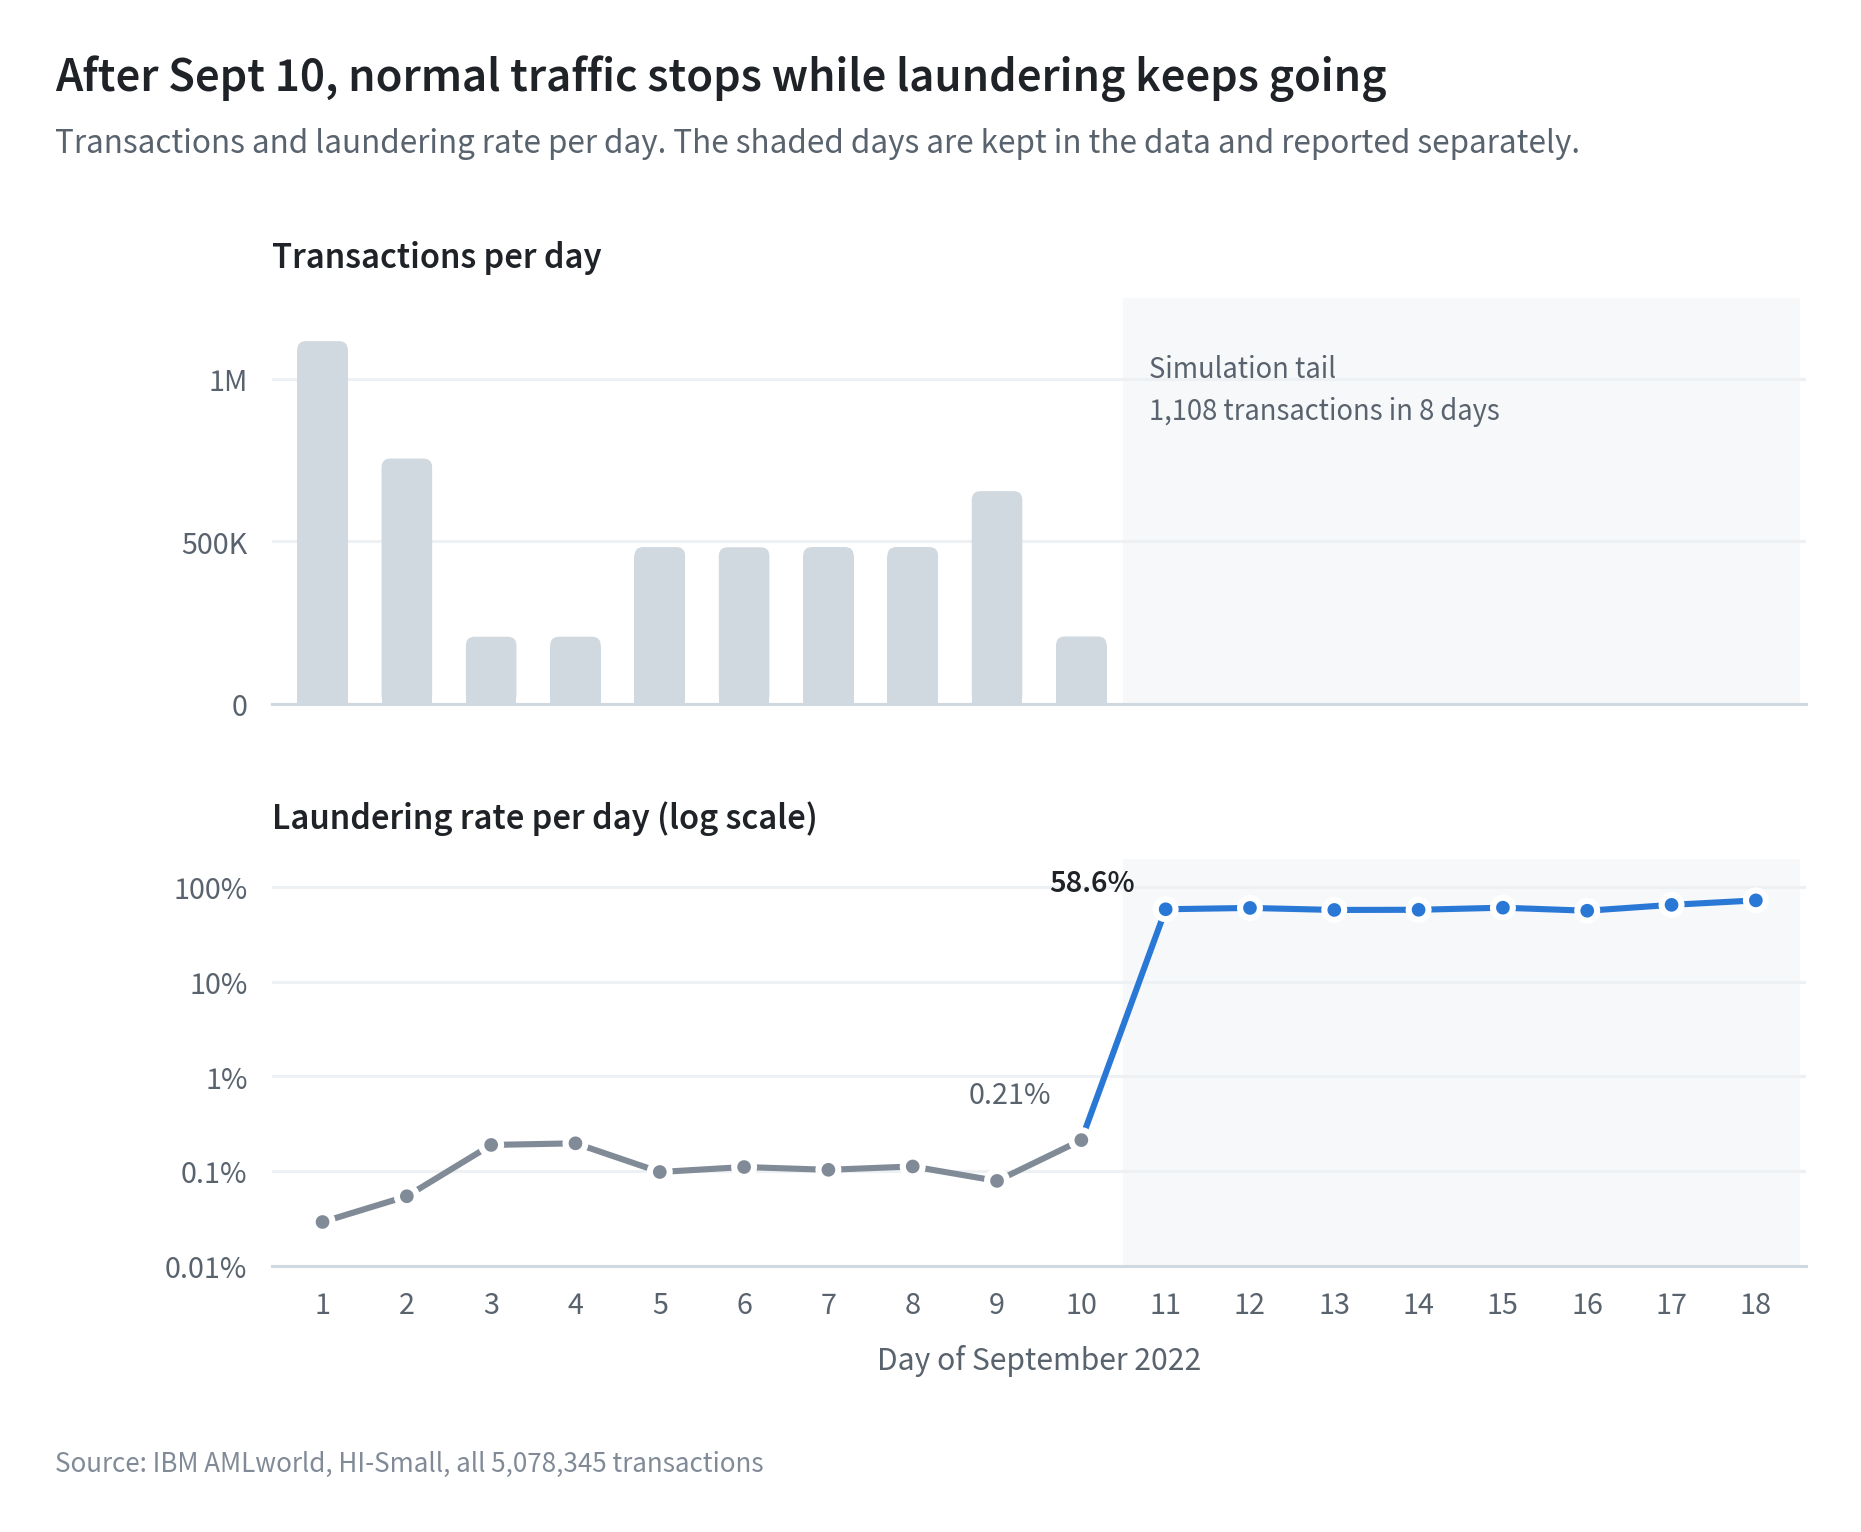

In [7]:
# Figure 1, saved to Drive and shown here.
display(Image(filename=str(figs.daily_volume(tx, cfg)), width=900))

## 3. Account key

A graph node must be one real account. Bank IDs in the transactions are padded with leading zeros inconsistently (010 and 0010 are the same bank), while accounts.csv uses the unpadded form. A few account numbers also appear at two different banks. The key is therefore the bank ID without leading zeros plus the account number, computed once when the data is ingested.

In [8]:
# All accounts seen as sender or receiver.
nodes = (
    tx.select(F.col("from_key").alias("key"), F.col("from_bank_id").alias("bank"),
              F.col("from_account").alias("account"))
      .unionByName(tx.select(F.col("to_key").alias("key"), F.col("to_bank_id").alias("bank"),
                             F.col("to_account").alias("account")))
      .distinct()
      .cache()
)
check("accounts (graph nodes)", nodes.count(), 515_088)
check("distinct account numbers", nodes.select("account").distinct().count(), 515_080)

# Account numbers shared by two different banks: real collisions, not padding.
shared = nodes.groupBy("account").agg(F.collect_set("bank").alias("banks")).filter(F.size("banks") > 1)
check("account numbers at two banks", shared.count(), 8)
shared.show(truncate=False)

# Every key must exist in accounts.csv, the independent source of accounts.
acct = load_accounts(spark, cfg)
check("rows in accounts.csv", acct.count(), 518_581)
missing = nodes.select("key").join(acct.select(F.col("account_key").alias("key")), "key", "left_anti")
check("keys missing from accounts.csv", missing.count(), 0)

# Transfers that look cross-bank on raw IDs but stay within one bank.
hidden = tx.filter((F.col("from_bank") != F.col("to_bank")) & (F.col("from_bank_id") == F.col("to_bank_id")))
check("same-bank transfers hidden by padding", hidden.count(), 77)
_ = nodes.unpersist()

ok       accounts (graph nodes): 515,088
ok       distinct account numbers: 515,080
ok       account numbers at two banks: 8
+---------+---------------+
|account  |banks          |
+---------+---------------+
|80A7FDE00|[28248, 27755] |
|80FA56340|[13858, 138832]|
|81211BC00|[142574, 1490] |
|8135B8250|[221731, 27444]|
|80FA55EF0|[13858, 138832]|
|81211BA20|[142574, 1490] |
|80A7FD400|[28248, 27755] |
|8135B8200|[221731, 27444]|
+---------+---------------+

ok       rows in accounts.csv: 518,581
ok       keys missing from accounts.csv: 0
ok       same-bank transfers hidden by padding: 77


## 4. Chronological split

Training uses the earliest days and testing the latest, as a bank would deploy a model. The split is on whole calendar days, so no transaction sits on a boundary. Dates come from configs/base.yaml.

In [9]:
# Size and laundering count of each split.
splits = (
    tx.groupBy("split")
      .agg(F.count("*").alias("rows"), F.sum("is_laundering").alias("laundering"),
           F.min("timestamp").alias("first"), F.max("timestamp").alias("last"))
      .orderBy("first")
      .toPandas()
      .set_index("split")
)
print(splits.to_string())

for name, rows, laundering in [("train", 3_248_921, 2_530), ("val", 965_524, 1_036), ("test", 863_900, 1_611)]:
    check(f"{name} rows", int(splits.loc[name, "rows"]), rows)
    check(f"{name} laundering", int(splits.loc[name, "laundering"]), laundering)

tail = tx.filter("is_tail").agg(F.count("*").alias("rows"), F.sum("is_laundering").alias("laundering")).first()
check("tail rows", tail["rows"], 1_108)
check("tail laundering", tail["laundering"], 655)

          rows  laundering      first                last
split                                                    
train  3248921        2530 2022-09-01 2022-09-06 23:59:00
val     965524        1036 2022-09-07 2022-09-08 23:59:00
test    863900        1611 2022-09-09 2022-09-18 16:18:00
ok       train rows: 3,248,921
ok       train laundering: 2,530
ok       val rows: 965,524
ok       val laundering: 1,036
ok       test rows: 863,900
ok       test laundering: 1,611
ok       tail rows: 1,108
ok       tail laundering: 655


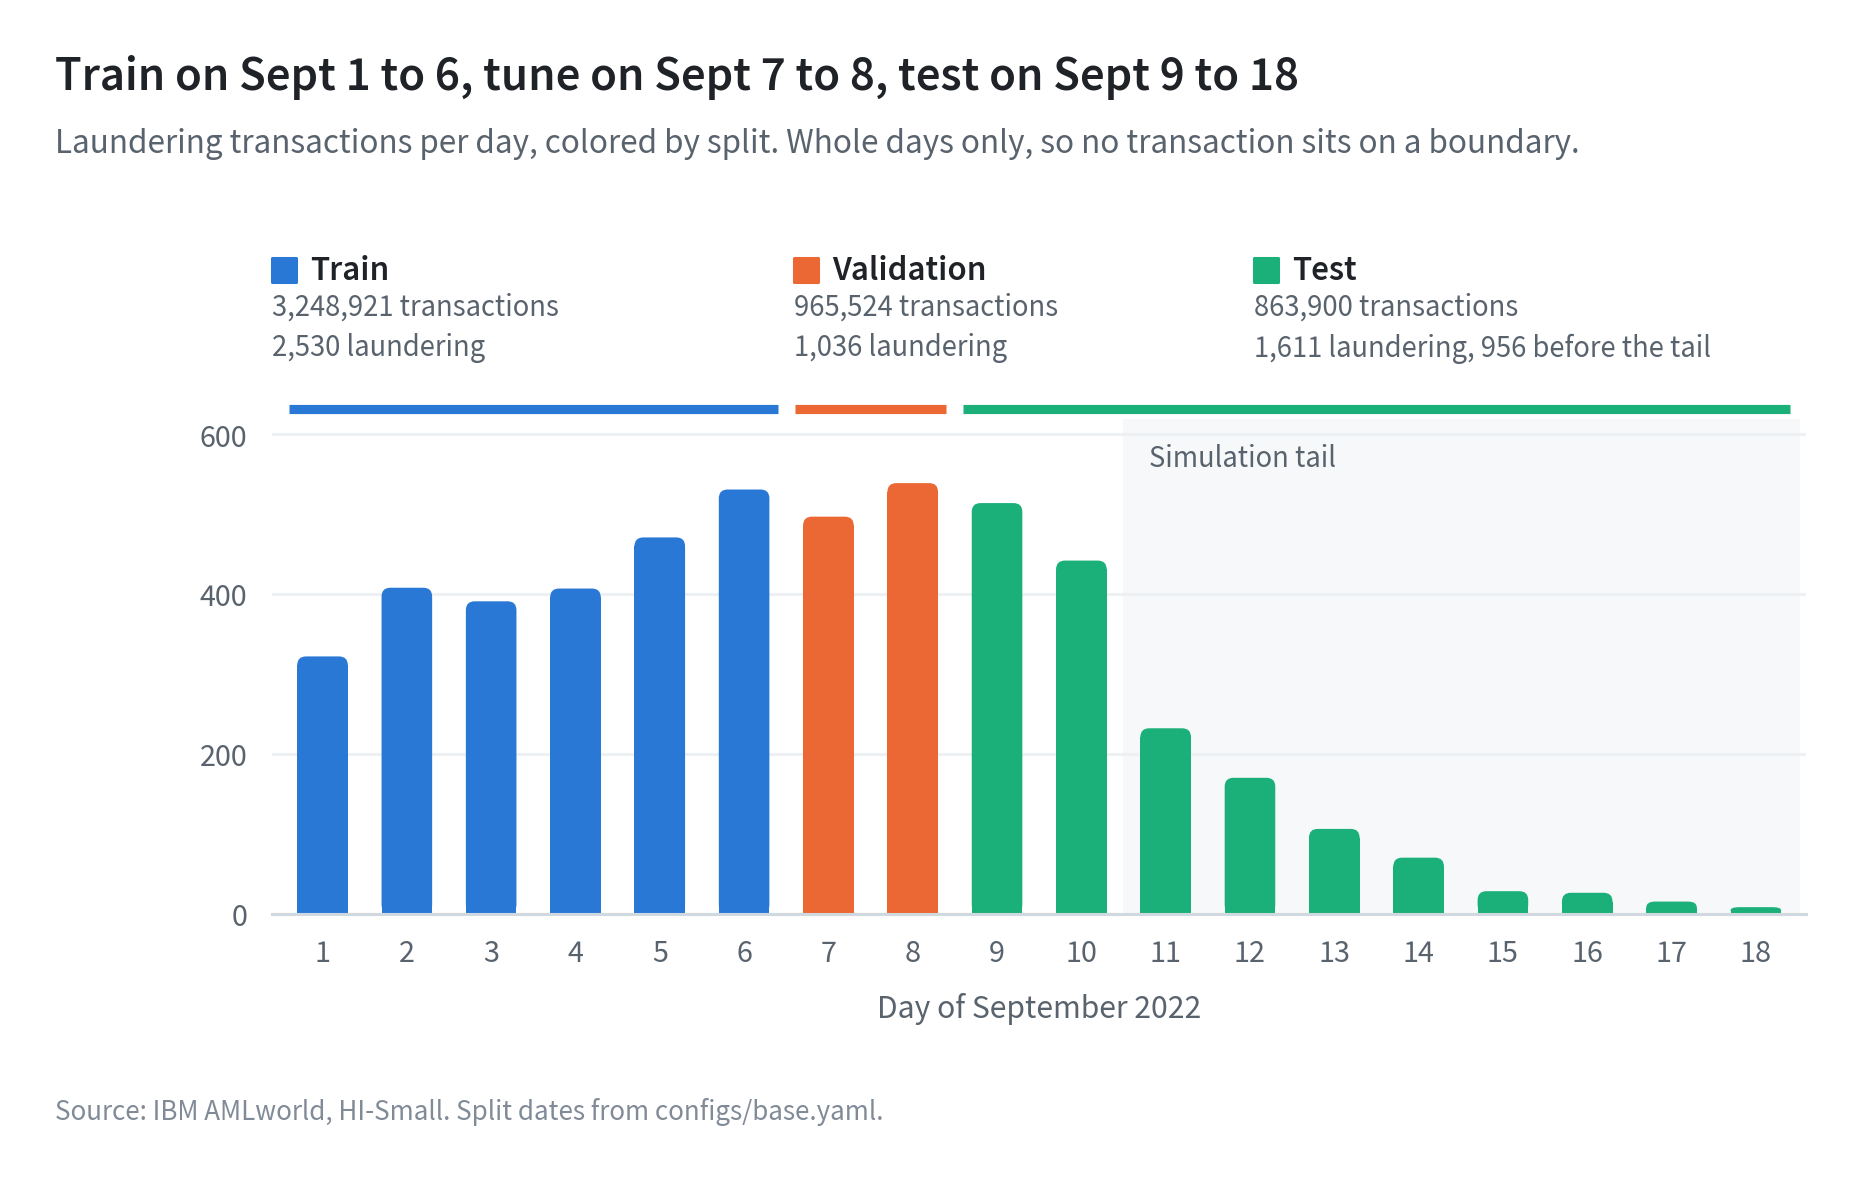

In [10]:
# Figure 2, saved to Drive and shown here.
display(Image(filename=str(figs.split_timeline(tx, cfg)), width=900))

## 5. Risk by payment format and currency

From here on, exploration that guides modeling uses training days only, so the test set does not influence feature choices. Lift compares a category's laundering rate with the overall training rate: 1 is average, above 1 is riskier.

In [11]:
# Training days only, kept in memory for the next two sections.
train = tx.filter(F.col("split") == "train").cache()
base_rate = train.select(F.avg("is_laundering")).first()[0]
print(f"training laundering rate: {base_rate:.3%}")


def risk_table(df, col, base_rate):
    """Transactions, laundering count, rate, and lift for each value of one column."""
    rate = F.col("laundering") / F.col("transactions")
    return (
        df.groupBy(col)
          .agg(F.count("*").alias("transactions"), F.sum("is_laundering").alias("laundering"))
          .withColumn("rate_pct", F.round(rate * 100, 3))
          .withColumn("lift", F.round(rate / F.lit(base_rate), 2))
          .orderBy(F.desc("lift"))
    )


risk_table(train, "payment_format", base_rate).show(truncate=False)
risk_table(train, "payment_currency", base_rate).show(20, truncate=False)

cross = train.withColumn("cross_currency", F.col("payment_currency") != F.col("receiving_currency"))
risk_table(cross, "cross_currency", base_rate).show()

training laundering rate: 0.078%
+--------------+------------+----------+--------+----+
|payment_format|transactions|laundering|rate_pct|lift|
+--------------+------------+----------+--------+----+
|ACH           |363584      |2104      |0.579   |7.43|
|Bitcoin       |93119       |34        |0.037   |0.47|
|Cash          |295797      |64        |0.022   |0.28|
|Cheque        |1120215     |205       |0.018   |0.24|
|Credit Card   |790260      |123       |0.016   |0.2 |
|Wire          |104890      |0         |0.0     |0.0 |
|Reinvestment  |481056      |0         |0.0     |0.0 |
+--------------+------------+----------+--------+----+

+-----------------+------------+----------+--------+----+
|payment_currency |transactions|laundering|rate_pct|lift|
+-----------------+------------+----------+--------+----+
|Saudi Riyal      |56522       |157       |0.278   |3.57|
|Canadian Dollar  |89342       |80        |0.09    |1.15|
|Euro             |748601      |626       |0.084   |1.07|
|Rupee       

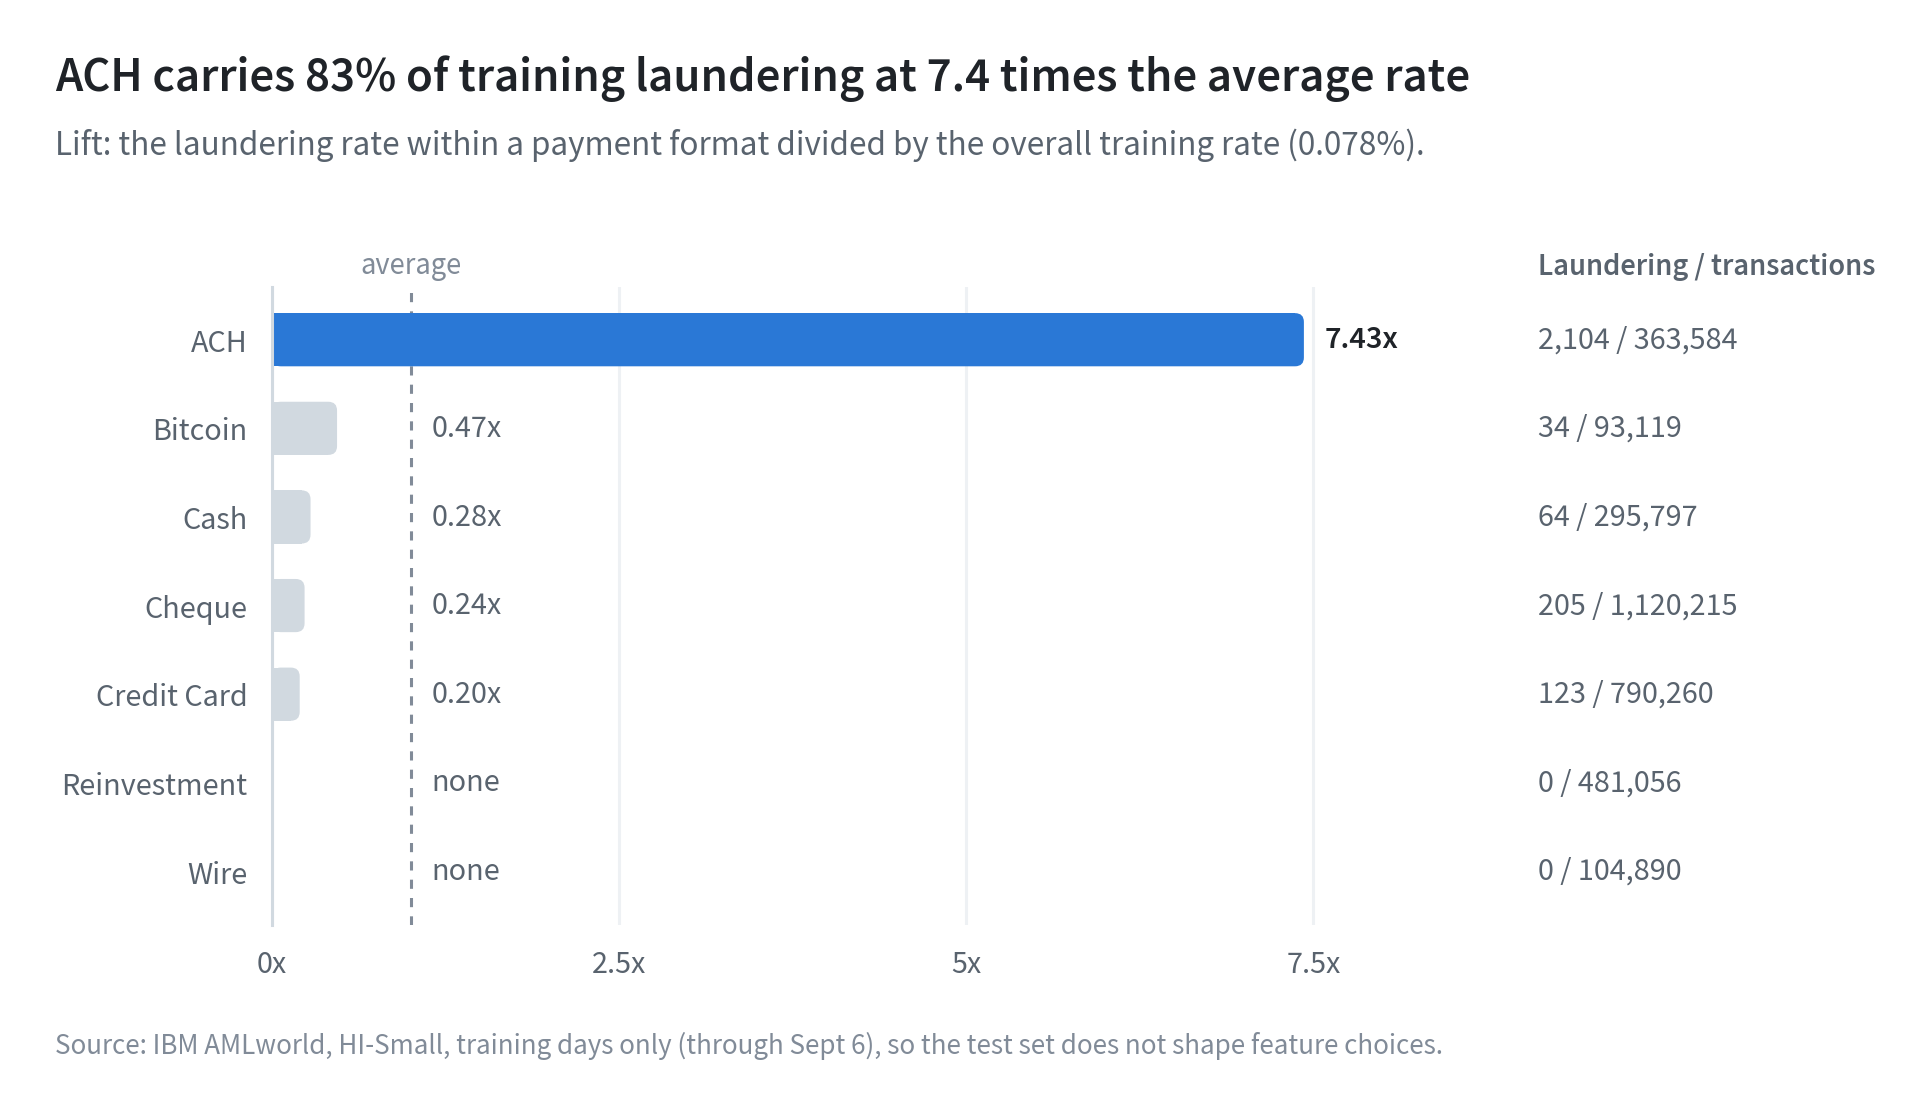

In [12]:
# Figure 3, saved to Drive and shown here.
display(Image(filename=str(figs.payment_format(tx, cfg)), width=900))

## 6. Amounts

Amounts in different currencies are not comparable, so this section uses US Dollar transfers only. Money is skewed, so the comparison uses percentiles rather than means.

In [13]:
# US Dollar on both sides, training days.
usd = train.filter((F.col("payment_currency") == "US Dollar") & (F.col("receiving_currency") == "US Dollar"))
usd_rate = usd.select(F.avg("is_laundering")).first()[0]
print(f"US Dollar training transactions: {usd.count():,}   laundering rate: {usd_rate:.3%}")

# Amount percentiles for normal (0) and laundering (1) transactions.
probs = [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
(
    usd.groupBy("is_laundering")
       .agg(*[F.round(F.percentile_approx("amount_paid", p, 10000), 2).alias(f"p{int(p * 100)}")
              for p in probs])
       .orderBy("is_laundering")
       .show()
)

# Round amounts: a multiple of 1,000, whole dollars, or an amount with cents.
rounded = usd.withColumn(
    "roundness",
    F.when(F.col("amount_paid") % 1000 == 0, "multiple of 1,000")
     .when(F.col("amount_paid") % 1 == 0, "whole dollars")
     .otherwise("has cents"),
)
risk_table(rounded, "roundness", usd_rate).show(truncate=False)

US Dollar training transactions: 1,188,953   laundering rate: 0.080%
+-------------+------+-------+-------+--------+--------+-------------+
|is_laundering|   p10|    p25|    p50|     p75|     p90|          p99|
+-------------+------+-------+-------+--------+--------+-------------+
|            0| 22.74| 151.46| 970.63| 6164.59|45376.83|    3431566.4|
|            1|521.49|1869.72|4832.76|12621.82|18927.02|2.003000028E7|
+-------------+------+-------+-------+--------+--------+-------------+

+-----------------+------------+----------+--------+----+
|roundness        |transactions|laundering|rate_pct|lift|
+-----------------+------------+----------+--------+----+
|has cents        |1172824     |936       |0.08    |1.0 |
|whole dollars    |16113       |12        |0.074   |0.93|
|multiple of 1,000|16          |0         |0.0     |0.0 |
+-----------------+------------+----------+--------+----+



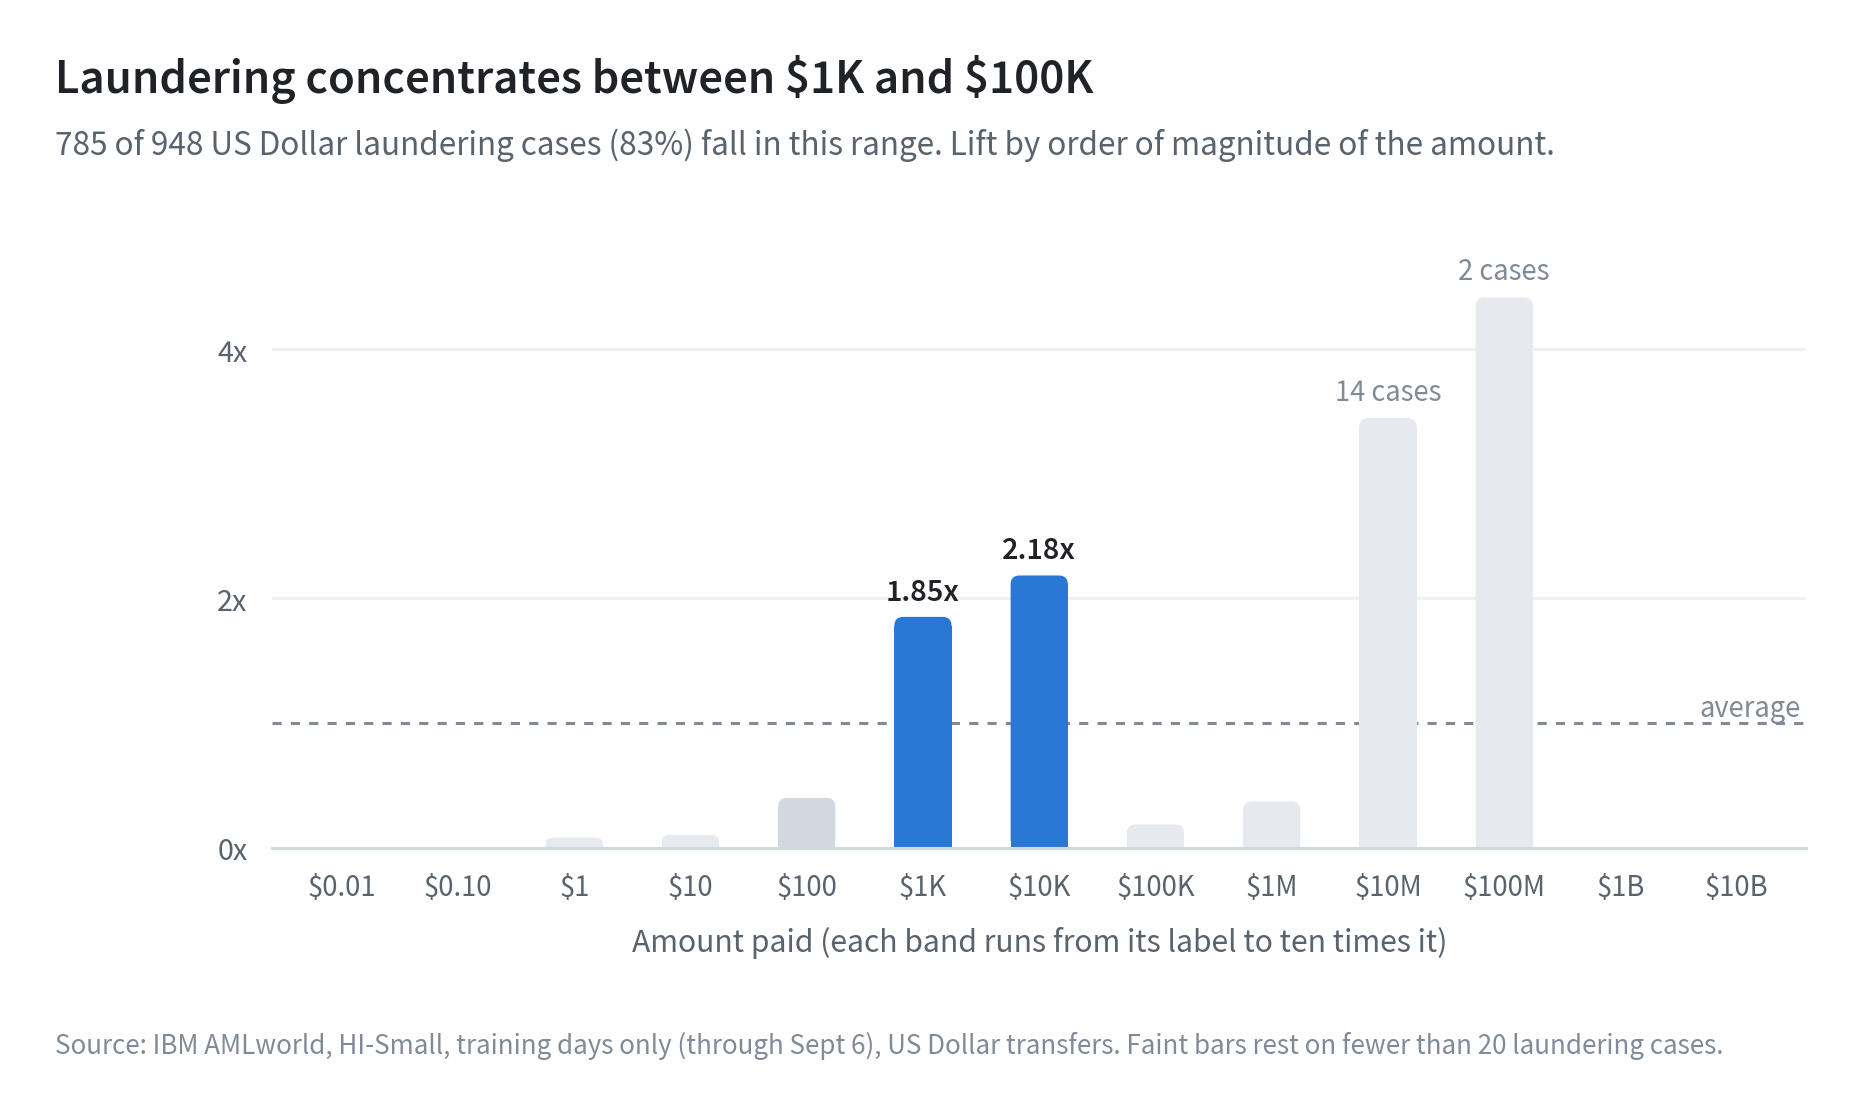

In [14]:
# Figure 4, saved to Drive and shown here.
display(Image(filename=str(figs.amount_bands(tx, cfg)), width=900))
_ = train.unpersist()

## 7. Laundering typologies

HI-Small_Patterns.txt groups laundering transactions into attempts of a named shape, such as fan-out or cycle. It is used for evaluation only: no bank has these labels, so using them as model features would be leakage. The file is small, so plain Python reads it; Spark joins it to the main table.

In [15]:
# Read the attempts: a BEGIN line names the typology, the lines after it are its transactions.
attempts, current = [], None
with open(raw_file(cfg, "patterns")) as f:
    for line in f:
        line = line.strip()
        if line.startswith("BEGIN LAUNDERING ATTEMPT"):
            typology = line.split(" - ", 1)[1].partition(":")[0].strip()
            current = {"typology": typology, "rows": []}
            attempts.append(current)
        elif line.startswith("END LAUNDERING ATTEMPT"):
            current = None
        elif line and current is not None:
            current["rows"].append(line.split(","))

check("attempts", len(attempts), 370)
check("pattern transactions", sum(len(a["rows"]) for a in attempts), 3_209)
check("malformed rows", sum(len(r) != 11 or r[10] != "1" for a in attempts for r in a["rows"]), 0)

sizes = pd.DataFrame({"typology": [a["typology"] for a in attempts],
                      "size": [len(a["rows"]) for a in attempts]})
print(sizes.groupby("typology")["size"]
           .agg(attempts="count", transactions="sum", median="median", largest="max")
           .sort_values("transactions", ascending=False).to_string())

ok       attempts: 370
ok       pattern transactions: 3,209
ok       malformed rows: 0
                attempts  transactions  median  largest
typology                                               
GATHER-SCATTER        51           716    14.0       28
SCATTER-GATHER        44           626    14.0       32
STACK                 43           466    10.0       30
FAN-OUT               48           342     7.0       16
FAN-IN                40           318     8.0       16
CYCLE                 54           287     4.0       12
BIPARTITE             49           263     4.0       15
RANDOM                41           191     3.0       11


In [16]:
# Match each pattern transaction to the main table by what it is: when, who, how much, and how.
cols = ["timestamp", "from_bank", "from_account", "to_bank", "to_account", "amount_received",
        "receiving_currency", "amount_paid", "payment_currency", "payment_format"]
rows = [(i, a["typology"], *r[:10]) for i, a in enumerate(attempts) for r in a["rows"]]
pat = (
    spark.createDataFrame(rows, ["attempt_id", "typology"] + cols)
         .withColumn("timestamp", F.to_timestamp("timestamp", TIMESTAMP_FORMAT))
         .withColumn("amount_paid", F.col("amount_paid").cast("double"))
         .withColumn("from_bank_id", canonical_bank("from_bank"))
         .withColumn("to_bank_id", canonical_bank("to_bank"))
         .withColumn("from_key", account_key("from_bank_id", "from_account"))
         .withColumn("to_key", account_key("to_bank_id", "to_account"))
)
KEY = ["timestamp", "from_key", "to_key", "amount_paid", "payment_currency", "payment_format"]

matched = tx.join(F.broadcast(pat.select(KEY + ["attempt_id", "typology"])), KEY, "inner").cache()
check("matched pattern transactions", matched.count(), 3_209)
check("matched rows not labeled laundering", matched.filter("is_laundering = 0").count(), 0)
covered = matched.select(KEY).distinct().count()
print(f"laundering in a named typology: {covered:,} of 5,177 ({covered / 5177:.1%})")

# Transactions per typology in each split.
(
    matched.groupBy("typology").pivot("split", ["train", "val", "test"]).count()
           .na.fill(0).orderBy("typology").show()
)

ok       matched pattern transactions: 3,209
ok       matched rows not labeled laundering: 0
laundering in a named typology: 3,209 of 5,177 (62.0%)
+--------------+-----+---+----+
|      typology|train|val|test|
+--------------+-----+---+----+
|     BIPARTITE|  148| 49|  66|
|         CYCLE|  122| 66|  99|
|        FAN-IN|  135| 60| 123|
|       FAN-OUT|  147| 64| 131|
|GATHER-SCATTER|  239| 96| 381|
|        RANDOM|   69| 38|  84|
|SCATTER-GATHER|  253|134| 239|
|         STACK|  199|150| 117|
+--------------+-----+---+----+



In [17]:
# The tail is made of typology attempts finishing after normal traffic stopped.
tail_named = matched.filter("is_tail").count()
check("tail laundering in a named typology", tail_named, 655)

core_all = tx.filter("split = 'test' AND NOT is_tail AND is_laundering = 1").count()
core_named = matched.filter("split = 'test' AND NOT is_tail").count()
print(f"test laundering before the tail in a named typology: {core_named} of {core_all} ({core_named / core_all:.1%})")

# Where each attempt starts and ends; the start defines the "new laundering" evaluation group.
first_tx = matched.groupBy("attempt_id").agg(F.min("timestamp").alias("timestamp"))
last_tx = matched.groupBy("attempt_id").agg(F.max("timestamp").alias("timestamp"))
starts = add_split(first_tx, cfg).select("attempt_id", F.col("split").alias("start_split"))
ends = add_split(last_tx, cfg).select("attempt_id", F.col("split").alias("end_split"))
(
    starts.join(ends, "attempt_id").groupBy("start_split")
          .pivot("end_split", ["train", "val", "test"]).count().na.fill(0).show()
)
matched.filter("split = 'test'").join(starts, "attempt_id").groupBy("start_split").count().show()

_ = matched.unpersist()

ok       tail laundering in a named typology: 655
test laundering before the tail in a named typology: 585 of 956 (61.2%)
+-----------+-----+---+----+
|start_split|train|val|test|
+-----------+-----+---+----+
|       test|    0|  0|  86|
|        val|    0| 13|  51|
|      train|  124| 50|  46|
+-----------+-----+---+----+

+-----------+-----+
|start_split|count|
+-----------+-----+
|       test|  721|
|        val|  344|
|      train|  175|
+-----------+-----+



## 8. Findings and decisions for modeling

**Data**
- 5,078,345 transactions over 18 days, 5,177 of them laundering (0.10%). Accuracy is meaningless at this rate, so models are judged on PR-AUC, minority-class F1, and recall at a fixed daily alert budget.
- After September 10 normal traffic stops; the tail (1,108 transactions, 655 laundering) is entirely laundering attempts finishing. It stays in the data, and every test metric is reported with and without it.

**Account key**
- Bank IDs are padded inconsistently; the canonical ID drops leading zeros and matches accounts.csv for all 515,088 accounts.
- Eight account numbers are shared by different banks, so the key is the canonical bank ID plus the account number.

**Split**
- Train September 1 to 6, validation 7 to 8, test 9 to 18, on whole days. 147 of 370 laundering attempts span more than one split, so no feature may memorize account identity, and test recall is also reported for attempts that started during the test period.

**Signals for Phase 2 features (training days only)**
- Payment format: ACH carries 83% of training laundering at 7.4 times the average rate; Wire and Reinvestment carry none.
- Currency: Saudi Riyal is the only clear outlier (lift 3.6); cross-currency transfers carry no laundering.
- Amount: laundering concentrates between $1,000 and $100,000; round amounts carry no signal.
- No calendar-date features; hour of day and day of week are allowed.

**Limitations to state in the README and the model card**
- Signals that are absolute in the simulator, such as formats that never launder, may not hold at a real bank.
- About 38% of laundering belongs to no named typology, so per-typology recall covers only part of the positives.

In [18]:
# Free the cached table.
_ = tx.unpersist()